# Tuplas de notícias e histórico de preços

Carrega em DataFrames os dados que alimentam os modelos de covariância
(`docs/metodo_covariancia.md`), para avaliação própria.

| DataFrame | origem | o que é |
|---|---|---|
| `tuplas` | `news.relations_linked` | todas as tuplas extraídas pelo LLM, com o ticker de cada lado e a marca de ruído (`noise` nulo = limpa) |
| `eventos` | `news.graph_events` | as tuplas limpas já como arestas do grafo (nós canônicos `src`/`dst`, `rel_class`, `w = ±strength`): **é o que os modelos usam** |
| `nos` | `news.graph_nodes` | os nós do grafo (tipo, ticker, nº de eventos) |
| `universo` | `news.universe` | o universo point-in-time (top-n ações por eventos) em cada rebalanceamento |
| `setores` | `news.sectors` | SIC e Fama-French 12/49 por ticker |
| `precos` | `news.prices` | preços diários (formato longo) dos tickers do universo + SPY e RSP, 2010–2023 |
| `retornos` | `news.returns` | retornos diários válidos, pivotados em data × ticker |

Só leitura: o banco é aberto em `read_only`.

In [1]:
import sys
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "newsmanager").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from newsmanager import config, query

cfg = config.load(ROOT / "config.toml") if (ROOT / "config.toml").exists() else config.load()
con = query.connect(cfg)            # read_only
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Tuplas

In [3]:
tuplas = con.execute("""
    SELECT published_at, year, unit_id, repr_doc_id, agent_a, agent_b, relation_type, direction, strength,
           noise, entity_a, ticker_a, kind_a, entity_b, ticker_b, kind_b, symbols
    FROM news.relations_linked ORDER BY published_at""").df()
tuplas["limpa"] = tuplas["noise"].isna()
print(f"{len(tuplas):,} tuplas, {tuplas['limpa'].mean():.1%} limpas, "
      f"{tuplas['published_at'].min():%Y-%m-%d} a {tuplas['published_at'].max():%Y-%m-%d}")
tuplas.tail()

1,270,582 tuplas, 86.1% limpas, 2006-10-23 a 2024-01-09


,published_at,year,unit_id,repr_doc_id,agent_a,agent_b,relation_type,direction,strength,noise,entity_a,ticker_a,kind_a,entity_b,ticker_b,kind_b,symbols,limpa
1270577,2024-01-09,2024,8d5e4a8d42448ed06bc781d7be4ceed0,b44ed784c5c4c2e543687f39db654502,U.S. government bond yield,technology stocks,affects,positive,0.6,NaN,US_GOVERNMENT_BOND_YIELD,NaN,macro,TECHNOLOGY_STOCKS,NaN,sector,[AMD],True
1270578,2024-01-09,2024,8d5e4a8d42448ed06bc781d7be4ceed0,b44ed784c5c4c2e543687f39db654502,ISM manufacturing Index,manufacturing activities,reflects,negative,0.8,NaN,ISM_MANUFACTURING_INDEX,NaN,macro,MANUFACTURING_ACTIVITIES,NaN,macro,[AMD],True
1270579,2024-01-09,2024,8d5e4a8d42448ed06bc781d7be4ceed0,b44ed784c5c4c2e543687f39db654502,ISM services Index,services activities,reflects,positive,0.8,NaN,ISM_SERVICES_INDEX,NaN,macro,SERVICES_ACTIVITIES,NaN,macro,[AMD],True
1270580,2024-01-09,2024,8d5e4a8d42448ed06bc781d7be4ceed0,b44ed784c5c4c2e543687f39db654502,Department of Labor,U.S. economy,reports,positive,0.6,NaN,DEPARTMENT_OF_LABOR,NaN,government,US_ECONOMY,NaN,macro,[AMD],True
1270581,2024-01-09,2024,8d5e4a8d42448ed06bc781d7be4ceed0,b44ed784c5c4c2e543687f39db654502,Federal Reserve Governor Michelle Bowman,market participants,uncertainty on,negative,0.6,NaN,FEDERAL_RESERVE_GOVERNOR_MICHELLE_BOWMAN,NaN,person,MARKET_PARTICIPANTS,NaN,macro,[AMD],True


In [4]:
eventos = con.execute("SELECT * EXCLUDE (v) FROM news.graph_events ORDER BY dt").df()
nos = con.execute("SELECT * EXCLUDE (v, graph_version) FROM news.graph_nodes").df()
print(f"{len(eventos):,} eventos, {len(nos):,} nós")
eventos.head()

1,064,801 eventos, 255,384 nós


,event_id,dt,unit_id,doc_id,src,dst,relation_type,rel_class,sign,strength,w,agent_a,agent_b
0,1,2006-10-23,41bd86217b7fc67b080f766be7fd2226,a0fa706303c5d5767ce93ef003d9f1a5,EUROPE,RUSSIA,strives for open investment climate,ownership,1,0.7,0.7,Europe,Russia
1,2,2006-10-23,41bd86217b7fc67b080f766be7fd2226,a0fa706303c5d5767ce93ef003d9f1a5,EUROPEAN_UNION_ENERGY_COMMISSIONER,GERMAN_ANTITRUST_OFFICE,backs,stance,1,0.8,0.8,European Union Energy Commissioner,German antitrust office
2,3,2006-10-23,41bd86217b7fc67b080f766be7fd2226,a0fa706303c5d5767ce93ef003d9f1a5,GERMAN_ANTITRUST_OFFICE,UTILITIES,challenges,competition,-1,0.8,-0.8,German antitrust office,utilities
3,4,2006-10-23,41bd86217b7fc67b080f766be7fd2226,a0fa706303c5d5767ce93ef003d9f1a5,ORGANIZATION_OF_PETROLEUM_EXPORTING_COUNTRIES,CRUDE_OIL,lowers,impact,-1,0.8,-0.8,Organization of Petroleum Exporting Countries,oil prices
4,5,2006-10-23,41bd86217b7fc67b080f766be7fd2226,a0fa706303c5d5767ce93ef003d9f1a5,RWE,NEW_POWER_PLANTS,discourages,other,-1,0.7,-0.7,RWE,new power plants


Exemplo: as tuplas entre duas ações (os dois sentidos).

In [5]:
a, b = "AAPL", "NVDA"
par = eventos[((eventos.src == a) & (eventos.dst == b)) | ((eventos.src == b) & (eventos.dst == a))]
print(f"{len(par)} eventos entre {a} e {b}")
par[["dt", "src", "dst", "relation_type", "rel_class", "strength", "w", "agent_a", "agent_b"]].tail(10)

33 eventos entre AAPL e NVDA


,dt,src,dst,relation_type,rel_class,strength,w,agent_a,agent_b
909491,2022-05-31,NVDA,AAPL,drives sentiment for,impact,0.7,0.7,Nvidia,Apple
920594,2022-07-15,NVDA,AAPL,competes with,competition,0.6,-0.6,Nvidia,Apple Inc.
995587,2023-05-18,NVDA,AAPL,competes with,competition,0.8,-0.8,Nvidia,Apple
999481,2023-06-01,AAPL,NVDA,compares to,competition,0.6,0.6,Apple Inc.,Nvidia
1006969,2023-06-28,AAPL,NVDA,competes with,competition,0.6,-0.6,Apple Inc.,Nvidia
1025829,2023-08-24,NVDA,AAPL,affects negatively,impact,0.4,-0.4,Nvidia,Apple Inc.
1025960,2023-08-24,NVDA,AAPL,influences,impact,0.6,0.6,NVIDIA Corporation NVDA,Apple Inc. AAPL
1033267,2023-09-15,NVDA,AAPL,competes with,competition,0.6,-0.6,Nvidia,Apple
1048040,2023-10-30,AAPL,NVDA,competes with,competition,0.4,-0.4,Apple,Nvidia
1052446,2023-11-15,NVDA,AAPL,compete with,competition,0.7,-0.7,NVDA,Apple Inc.


## 2. Universo e setores

In [6]:
universo = con.execute("SELECT * FROM news.universe ORDER BY n_target, rebalance_date, rank").df()
setores = con.execute("SELECT * FROM news.sectors").df()
universo.groupby("n_target").agg(tickers=("ticker", "nunique"), meses=("rebalance_date", "nunique"),
                                 inicio=("rebalance_date", "min"), fim=("rebalance_date", "max"))

,tickers,meses,inicio,fim
n_target,,,,
50,166,156,2011-01-03,2023-12-01
100,315,156,2011-01-03,2023-12-01
200,651,156,2011-01-03,2023-12-01


## 3. Preços e retornos

Tickers: todos os que entram em algum universo (n = 50, 100 ou 200), mais SPY e
RSP. O filtro vai como lista literal (com `IN (SELECT unnest(?))` o DuckDB não
poda o Parquet e a consulta leva minutos).

- `ret` em `precos` é o retorno ajustado; `flag` marca os dias inválidos (emendas
  da coleta, saltos). `retornos` tem só os retornos válidos, que são os usados
  nos backtests.

In [7]:
tickers = sorted(set(universo["ticker"]) | {"SPY", "RSP"})
lista = ", ".join(f"'{t}'" for t in tickers)
precos = con.execute(f"""
    SELECT * FROM news.prices
    WHERE ticker IN ({lista}) AND date BETWEEN DATE '2010-01-01' AND DATE '2023-12-31'
    ORDER BY ticker, date""").df()
ret_long = con.execute(f"""
    SELECT ticker, date, ret FROM news.returns
    WHERE ticker IN ({lista}) AND date BETWEEN DATE '2010-01-01' AND DATE '2023-12-31'""").df()
retornos = ret_long.pivot(index="date", columns="ticker", values="ret").sort_index()
print(f"precos: {len(precos):,} linhas, {precos['ticker'].nunique()} tickers; "
      f"retornos: {retornos.shape[0]} pregões x {retornos.shape[1]} tickers")
precos.head()

precos: 1,996,766 linhas, 653 tickers; retornos: 3517 pregões x 653 tickers


,ticker,date,close,adj_close,volume,dollar_volume,ret_raw,ret,flag,batch
0,AA,2010-01-04,40.009949,37.018944,10773700.0,4.310552e+08,0.032878,0.032878,NaN,old
1,AA,2010-01-05,38.760391,35.862801,20777100.0,8.053285e+08,-0.031231,-0.031231,NaN,old
2,AA,2010-01-06,40.778912,37.730419,19451600.0,7.932151e+08,0.052077,0.052077,NaN,old
3,AA,2010-01-07,39.913830,36.930008,16080500.0,6.418343e+08,-0.021214,-0.021214,NaN,old
4,AA,2010-01-08,40.899059,37.841591,13835200.0,5.658467e+08,0.024684,0.024684,NaN,old


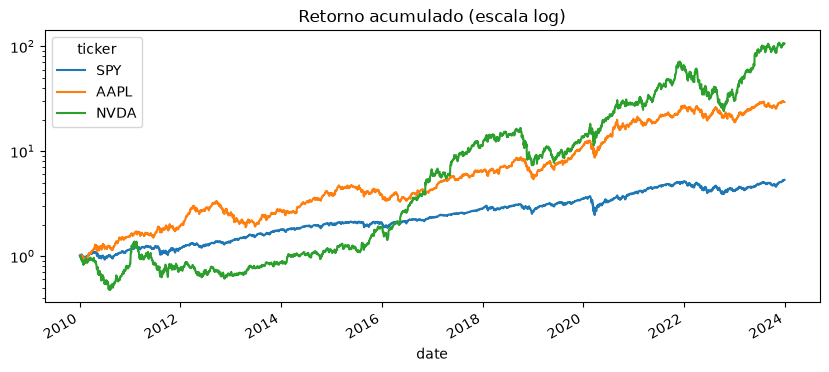

In [7]:
ax = (1 + retornos[["SPY", "AAPL", "NVDA"]].fillna(0)).cumprod().plot(logy=True, figsize=(10, 4),
                                                                       title="Retorno acumulado (escala log)")

In [9]:
### Backtest parameters

rebalance_frequency = 21
inSample = 252

start_date = '2019-01-01'
end_date = '2023-01-01'

In [18]:
comp = pd.read_csv(ROOT / "data/reference/sp500/sp500_historical_components.csv", parse_dates=["date"])
comp["tickers"] = comp["tickers"].str.split(",").apply(lambda xs: sorted({x.replace(".", "-") for x in xs}))

def membros(data):
    """Membros do S&P 500 no último registro estritamente antes de `data`."""
    return comp.loc[comp["date"] < pd.Timestamp(data), "tickers"].iloc[-1]

# preços e retornos de todos os que foram membros entre 2009 e 2023 (+ SPY)
sp_tickers = sorted(set().union(*comp.loc[comp["date"].between("2009-01-01", "2023-12-31"), "tickers"]) | {"SPY"})
lista = ", ".join(f"'{t}'" for t in sp_tickers)
precos = con.execute(f"""
    SELECT ticker, date, adj_close, ret, flag FROM news.prices
    WHERE ticker IN ({lista}) AND date BETWEEN DATE '2009-01-01' AND DATE '2023-12-31'""").df()
precos["date"] = pd.to_datetime(precos["date"])
retornos = (con.execute(f"""
    SELECT ticker, date, ret FROM news.returns
    WHERE ticker IN ({lista}) AND date BETWEEN DATE '2009-01-01' AND DATE '2023-12-31'""").df()
    .pivot(index="date", columns="ticker", values="ret"))
retornos.index = pd.to_datetime(retornos.index)
calendario = pd.to_datetime(con.execute("SELECT date FROM news.trading_calendar ORDER BY date").df()["date"])
print(f"{len(sp_tickers)} tickers que passaram pelo índice em 2009-2023; {retornos.shape[1]} com retornos no FNSPID")

def janela(data, n=252, x=21, min_cobertura=0.95):
    """Preços (adj_close) e retornos de n pregões antes de `data` (exclusive)
    + x pregões a partir de `data` (inclusive), para os membros do S&P 500 em
    `data` com retorno válido em >= min_cobertura dos n + x pregões."""
    t = pd.Timestamp(data)
    antes = calendario[calendario < t].iloc[-n:]
    depois = calendario[calendario >= t].iloc[:x]
    if len(antes) < n or len(depois) < x:
        raise ValueError(f"{len(antes)} pregões antes e {len(depois)} depois de {t:%Y-%m-%d}")
    dias = pd.DatetimeIndex(pd.concat([antes, depois]))
    tk = [s for s in membros(t) if s in retornos.columns]
    r = retornos.reindex(index=dias, columns=tk)
    ok = r.notna().mean() >= min_cobertura
    r = r.loc[:, ok]
    px = (precos[precos["date"].between(dias[0], dias[-1]) & precos["ticker"].isin(r.columns)]
          .pivot(index="date", columns="ticker", values="adj_close").reindex(index=dias, columns=r.columns))
    print(f"{t:%Y-%m-%d}: {len(membros(t))} membros, {len(tk)} com preço no FNSPID, {ok.sum()} com dados no período")
    return px, r

px, r = janela(start_date, n=inSample, x=rebalance_frequency)
print(px.shape, px.index.min(), px.index.max())

814 tickers que passaram pelo índice em 2009-2023; 615 com retornos no FNSPID
2019-01-01: 505 membros, 460 com preço no FNSPID, 458 com dados no período
(273, 458) 2017-12-29 00:00:00 2019-01-31 00:00:00


In [20]:
px.ffill(inplace=True)
px.bfill(inplace=True)
px

ticker,A,AAL,AAP,AAPL,ABBV,ABC,ABMD,ABT,ACN,ADBE,ADI,ADM,ADP,ADS,ADSK,...,WFC,WHR,WMT,WRK,WY,XEC,XEL,XLNX,XOM,XRAY,XYL,YUM,ZBH,ZION,ZTS
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-12-29,65.626320,50.711876,99.089966,163.869995,85.663902,88.159889,187.410004,54.895420,147.931244,175.240005,85.038956,37.303631,111.757172,244.713364,104.830002,...,60.669998,154.499146,98.750000,57.220558,31.759834,117.763931,44.711452,64.636711,74.119148,64.488045,68.199997,78.126450,118.221024,47.581043,70.942154
2018-01-02,66.243683,51.647556,105.451424,166.804016,87.169739,90.291420,192.490005,56.549885,148.655960,177.699997,86.232903,37.312943,110.612801,246.499420,107.120003,...,61.090000,153.903702,98.589996,58.578419,31.795868,121.142136,44.432648,65.077721,75.350937,65.771332,68.070000,78.116875,121.542229,47.459354,70.676254
2018-01-03,67.929161,51.014027,106.405663,166.774963,88.533836,90.627441,195.820007,56.674927,149.342056,181.039993,87.302719,37.024418,111.814392,251.075470,109.379997,...,61.560001,154.682404,99.449997,59.203049,32.075089,121.808121,44.135258,66.381584,76.830833,65.546021,68.900002,78.049866,122.384781,47.403194,71.001228
2018-01-04,67.419609,51.335667,110.331879,167.549622,88.028946,90.425827,199.250000,56.578735,151.110382,183.220001,87.207191,37.648003,112.882484,254.917847,112.070000,...,62.330002,154.664078,99.540001,60.687637,31.813879,124.182510,43.791389,67.579971,76.937187,65.536232,69.360001,78.844452,122.208435,47.599766,71.424683
2018-01-05,68.497528,51.316177,111.504761,169.457214,89.561348,91.520370,202.320007,56.742260,152.356918,185.339996,87.560585,37.396709,112.815720,255.603302,110.839996,...,62.750000,154.352600,100.129997,60.932064,31.768848,123.371735,43.484699,71.088882,76.875137,66.457069,69.230003,79.303955,123.423271,47.618484,72.242035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-25,72.841270,34.423378,152.555389,155.056747,75.031906,77.808289,349.369995,70.016365,149.380783,244.949997,95.183632,41.907726,132.839478,173.351212,142.080002,...,50.130001,118.435059,96.940002,39.509289,24.097391,73.535332,48.560307,107.902977,66.189941,40.910080,69.860001,90.307495,106.139091,46.475887,84.062149
2019-01-28,72.465431,35.988075,154.188278,153.621765,71.864426,78.257599,336.899994,67.949814,149.764450,241.850006,94.862038,42.339069,131.953278,174.375427,140.770004,...,49.820000,117.857422,97.059998,38.939396,24.191154,72.573639,48.473831,106.915543,65.746948,39.951786,69.349998,90.190605,104.587654,46.590450,83.029861
2019-01-29,72.752251,35.712532,154.715973,152.029510,72.171867,77.691063,330.380005,68.579620,149.548050,238.270004,94.540443,42.377415,130.492538,173.448730,140.160004,...,49.849998,129.249237,96.709999,38.724522,24.238037,72.884483,48.656391,106.944878,65.996117,40.584068,70.489998,90.268539,104.409790,46.065361,83.784233


In [22]:
returns = px.pct_change().dropna()

# in-sample: pregões antes de start_date; out-of-sample: a partir de start_date (inclusive)
returns_in = returns[returns.index < pd.Timestamp(start_date)]
returns_out = returns[returns.index >= pd.Timestamp(start_date)]
print(f"in-sample:     {len(returns_in)} pregões, {returns_in.index.min():%Y-%m-%d} a {returns_in.index.max():%Y-%m-%d}")
print(f"out-of-sample: {len(returns_out)} pregões, {returns_out.index.min():%Y-%m-%d} a {returns_out.index.max():%Y-%m-%d}")
returns_out

in-sample:     251 pregões, 2018-01-02 a 2018-12-31
out-of-sample: 21 pregões, 2019-01-02 a 2019-01-31


ticker,A,AAL,AAP,AAPL,ABBV,ABC,ABMD,ABT,ACN,ADBE,ADI,ADM,ADP,ADS,ADSK,...,WFC,WHR,WMT,WRK,WY,XEC,XEL,XLNX,XOM,XRAY,XYL,YUM,ZBH,ZION,ZTS
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-01-02,-0.026238,0.011523,0.002921,0.001141,-0.032108,0.000672,-0.046394,-0.039126,-0.002979,-0.007382,0.001048,-0.000488,-0.007474,0.035315,0.002721,...,0.018663,0.009825,0.002040,0.029926,-0.015096,0.017194,-0.021311,0.019725,0.021997,0.018275,-0.003147,-0.005222,-0.013883,0.020618,-0.012392
2019-01-03,-0.036840,-0.074507,0.031219,-0.099607,-0.032948,-0.014506,-0.024745,-0.047194,-0.034142,-0.039498,-0.060405,-0.004396,-0.030198,-0.025293,-0.055133,...,-0.007882,-0.003336,-0.005142,-0.016971,0.033906,-0.013873,-0.003940,-0.037651,-0.015354,0.000528,-0.034281,-0.025153,-0.018088,-0.005531,-0.034564
2019-01-04,0.034614,0.065868,-0.024808,0.042689,0.032217,0.011585,0.036885,0.028541,0.038884,0.048632,0.024278,0.023056,0.039854,0.067679,0.052770,...,0.029633,0.048903,0.006246,0.043160,0.034142,0.049968,0.009786,0.046303,0.036870,0.029016,0.042192,0.026027,0.034153,0.030713,0.039235
2019-01-07,0.021234,0.028402,0.014672,-0.002226,0.014595,0.007141,0.004339,0.014976,0.003473,0.013573,0.006288,0.005035,-0.005410,-0.000062,0.034612,...,-0.006465,0.029162,0.011772,0.001755,0.019983,0.022024,-0.004330,0.026415,0.005200,0.017944,-0.014789,-0.001093,0.000385,0.003989,0.006017
2019-01-08,0.014660,-0.016085,-0.006950,0.019063,0.004648,0.010702,0.011499,-0.012006,0.025290,0.014918,0.024396,0.018607,0.005899,0.017379,0.008665,...,-0.002099,0.022479,0.006981,-0.002753,0.005963,0.016124,0.011596,-0.019051,0.007271,-0.006799,0.009401,-0.001970,-0.022425,0.009114,0.014894
2019-01-09,0.020935,0.030845,0.027559,0.016982,-0.032823,0.010192,0.056466,0.016691,0.005030,0.011819,0.025340,0.008665,0.000914,0.021885,0.021663,...,0.005469,0.023332,-0.003256,-0.021084,0.003387,0.018983,-0.007984,0.008972,0.005275,0.005325,0.016224,-0.000439,0.008172,0.008569,-0.003582
2019-01-10,0.009386,-0.041293,0.003892,0.003196,0.004441,-0.004193,-0.003775,-0.005184,0.007884,0.009939,0.013844,0.006965,0.007914,-0.005176,-0.000439,...,-0.001046,0.008396,0.000738,0.033077,0.025316,0.025469,0.016715,0.017222,-0.005109,0.009836,0.018625,0.007132,0.012891,0.004822,-0.003827
2019-01-11,0.006867,-0.007491,-0.034228,-0.009818,0.001247,0.007368,-0.033808,0.003619,-0.005374,-0.000925,0.016364,-0.004842,-0.006115,0.001435,0.000219,...,0.002513,0.004734,-0.001264,0.016381,-0.003704,0.002554,0.000406,0.006086,-0.004580,0.016733,0.005950,-0.009260,0.005399,0.005256,0.001863
2019-01-14,-0.008951,-0.002830,-0.004391,-0.015037,-0.028427,0.003919,-0.026405,-0.010723,-0.008890,-0.012587,-0.028425,-0.007183,-0.005697,0.004001,-0.014553,...,0.011489,0.006824,0.001160,-0.018315,-0.005370,0.019677,-0.007304,-0.003959,-0.001255,-0.015721,-0.002308,-0.010337,-0.015247,0.007502,-0.018127


In [24]:
# tuplas do período in-sample que ligam duas ações de returns_in
# (eventos limpos do grafo; o nó de uma ação é o próprio ticker)
acoes = set(returns_in.columns)
ini_in = px.index.min()                       # primeiro pregão da janela in-sample
tuplas_in = eventos[
    (pd.to_datetime(eventos["dt"]) >= ini_in)
    & (pd.to_datetime(eventos["dt"]) < pd.Timestamp(start_date))
    & eventos["src"].isin(acoes) & eventos["dst"].isin(acoes)
    & (eventos["src"] != eventos["dst"])
].copy()
print(f"{len(tuplas_in):,} tuplas entre {ini_in:%Y-%m-%d} e {pd.Timestamp(start_date) - pd.Timedelta(days=1):%Y-%m-%d}, "
      f"{tuplas_in[['src', 'dst']].apply(frozenset, axis=1).nunique():,} pares distintos, "
      f"{len(set(tuplas_in['src']) | set(tuplas_in['dst']))} ações envolvidas")
tuplas_in[["dt", "src", "dst", "relation_type", "rel_class", "strength", "w", "agent_a", "agent_b", "doc_id"]]

3,401 tuplas entre 2017-12-29 e 2018-12-31, 1,100 pares distintos, 363 ações envolvidas


,dt,src,dst,relation_type,rel_class,strength,w,agent_a,agent_b,doc_id
658906,2017-12-29,TRIP,GOOG,competes with,competition,0.7,-0.7,TripAdvisor Inc,Alphabet,9de8ded87244f8066c75fcf49a41bd30
658907,2017-12-29,TRIP,EXPE,competes with,competition,0.7,-0.7,TripAdvisor Inc,Expedia,9de8ded87244f8066c75fcf49a41bd30
658927,2017-12-29,MCO,BDX,downgrades,analyst,0.8,-0.8,Moody's Investors Service,"Becton, Dickinson and Company",12ea9be8e72e30aa5de1f85f15b25385
658985,2017-12-29,STZ,FAST,competed with,competition,0.4,-0.4,Constellation Brands Inc,Fastenal Company,e2d02790383d41a58d7894efe3897fc5
658986,2017-12-29,STZ,MCD,competed with,competition,0.4,-0.4,Constellation Brands Inc,McDonald's Corporation,e2d02790383d41a58d7894efe3897fc5
...,...,...,...,...,...,...,...,...,...,...
710865,2018-12-31,KHC,CAG,competes with,competition,0.4,-0.4,Kraft Heinz,Conagra Brands,549c84606282866c1f3b0e47694ff021
710866,2018-12-31,KHC,GIS,competes with,competition,0.4,-0.4,Kraft Heinz,General Mills,549c84606282866c1f3b0e47694ff021
710921,2018-12-31,NDAQ,AMD,affects,impact,0.6,-0.6,Nasdaq,AMD,a2c525a21c0499c24d6cff545479c52c
710925,2018-12-31,MO,PM,complicates partnership with,partnership,0.8,-0.8,Altria,Philip Morris International,db8f392e43bac0ee48b792f3156b44bb


In [ ]:
# w médio por par (w = ±strength, com o sinal da relação; sem ordem: AAPL->NVDA e NVDA->AAPL contam juntas)
par = tuplas_in.assign(a=tuplas_in[["src", "dst"]].min(axis=1), b=tuplas_in[["src", "dst"]].max(axis=1))
strength_par = par.groupby(["a", "b"]).agg(w_medio=("w", "mean"), n_tuplas=("w", "size")).reset_index()

# matriz simétrica ações x ações (mesma ordem de returns_in); NaN = par sem tupla no período
acoes_ord = list(returns_in.columns)
pos = {t: k for k, t in enumerate(acoes_ord)}
M = np.full((len(acoes_ord), len(acoes_ord)), np.nan)
i, j = strength_par["a"].map(pos).to_numpy(), strength_par["b"].map(pos).to_numpy()
M[i, j] = M[j, i] = strength_par["w_medio"].to_numpy()
S_news = pd.DataFrame(M, index=acoes_ord, columns=acoes_ord)

print(f"{len(strength_par):,} pares com tupla de {len(acoes_ord) * (len(acoes_ord) - 1) // 2:,} possíveis "
      f"({len(strength_par) / (len(acoes_ord) * (len(acoes_ord) - 1) / 2):.1%})")
strength_par.sort_values("n_tuplas", ascending=False).head(10)

In [27]:
strength_par

,a,b,strength_media,n_tuplas
0,A,LH,0.700000,1
1,AAL,ALK,0.600000,2
2,AAL,BA,0.800000,1
3,AAL,DAL,0.614286,7
4,AAL,LUV,0.575000,4
...,...,...,...,...
1095,TROW,XOM,0.800000,1
1096,TXN,XLNX,0.700000,1
1097,UAA,VFC,0.600000,1
1098,UNP,UPS,0.600000,1


In [32]:
covariance = returns_in.cov()
covariance

ticker,A,AAL,AAP,AAPL,ABBV,ABC,ABMD,ABT,ACN,ADBE,ADI,ADM,ADP,ADS,ADSK,...,WFC,WHR,WMT,WRK,WY,XEC,XEL,XLNX,XOM,XRAY,XYL,YUM,ZBH,ZION,ZTS
ticker,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A,0.000291,0.000168,0.000104,0.000146,0.000151,0.000112,0.000231,0.000151,0.000155,0.000234,0.000171,0.000080,0.000141,0.000143,0.000234,...,0.000097,0.000114,0.000079,0.000149,0.000082,0.000120,0.000009,0.000202,0.000103,0.000075,0.000149,0.000095,0.000130,0.000101,0.000149
AAL,0.000168,0.000637,0.000149,0.000170,0.000137,0.000152,0.000182,0.000146,0.000149,0.000252,0.000213,0.000118,0.000146,0.000172,0.000282,...,0.000157,0.000198,0.000109,0.000202,0.000103,0.000116,0.000005,0.000310,0.000078,0.000127,0.000184,0.000102,0.000125,0.000175,0.000164
AAP,0.000104,0.000149,0.000411,0.000113,0.000119,0.000115,0.000160,0.000099,0.000116,0.000157,0.000106,0.000093,0.000095,0.000128,0.000157,...,0.000095,0.000127,0.000074,0.000118,0.000067,0.000084,0.000012,0.000148,0.000073,0.000070,0.000081,0.000065,0.000087,0.000110,0.000113
AAPL,0.000146,0.000170,0.000113,0.000328,0.000128,0.000102,0.000264,0.000147,0.000163,0.000271,0.000185,0.000089,0.000151,0.000134,0.000251,...,0.000111,0.000109,0.000084,0.000123,0.000106,0.000146,0.000011,0.000247,0.000109,0.000092,0.000118,0.000087,0.000127,0.000114,0.000140
ABBV,0.000151,0.000137,0.000119,0.000128,0.000492,0.000166,0.000217,0.000157,0.000156,0.000189,0.000145,0.000096,0.000117,0.000140,0.000183,...,0.000128,0.000117,0.000100,0.000150,0.000077,0.000124,0.000017,0.000181,0.000108,0.000142,0.000144,0.000080,0.000150,0.000141,0.000158
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,0.000149,0.000184,0.000081,0.000118,0.000144,0.000097,0.000194,0.000136,0.000129,0.000185,0.000130,0.000080,0.000117,0.000133,0.000212,...,0.000095,0.000122,0.000079,0.000174,0.000075,0.000125,0.000005,0.000166,0.000108,0.000079,0.000270,0.000090,0.000114,0.000101,0.000155
YUM,0.000095,0.000102,0.000065,0.000087,0.000080,0.000052,0.000147,0.000094,0.000093,0.000147,0.000078,0.000057,0.000092,0.000077,0.000142,...,0.000064,0.000073,0.000066,0.000087,0.000059,0.000078,0.000023,0.000113,0.000069,0.000042,0.000090,0.000152,0.000073,0.000069,0.000101
ZBH,0.000130,0.000125,0.000087,0.000127,0.000150,0.000118,0.000177,0.000136,0.000121,0.000177,0.000122,0.000081,0.000115,0.000112,0.000193,...,0.000090,0.000097,0.000070,0.000117,0.000100,0.000123,0.000018,0.000149,0.000081,0.000108,0.000114,0.000073,0.000219,0.000101,0.000118


In [34]:
# w médio por par no mesmo formato de `covariance`: todas as ações de returns_in, mesma ordem,
# mesmo nome de índice/colunas. Par sem tupla no período e diagonal = 0.
strength_matrix = (S_news.reindex(index=covariance.index, columns=covariance.columns)
                   .fillna(0.0)
                   .rename_axis(index=covariance.index.name, columns=covariance.columns.name))
assert strength_matrix.shape == covariance.shape and (strength_matrix.index == covariance.index).all()
assert np.allclose(strength_matrix.values, strength_matrix.values.T)
print(f"{strength_matrix.shape[0]} ações; {(strength_matrix.values != 0).sum() // 2:,} pares com valor "
      f"de {len(covariance) * (len(covariance) - 1) // 2:,}")
strength_matrix

458 ações; 1,100 pares com valor de 104,653


ticker,A,AAL,AAP,AAPL,ABBV,ABC,ABMD,ABT,ACN,ADBE,ADI,ADM,ADP,ADS,ADSK,...,WFC,WHR,WMT,WRK,WY,XEC,XEL,XLNX,XOM,XRAY,XYL,YUM,ZBH,ZION,ZTS
ticker,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAP,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.64,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAPL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.8,0.6,0.0,0.0,0.0,0.0,0.0,...,0.0,0.8,0.80,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ABBV,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
YUM,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ZBH,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [33]:
correlation = returns_in.corr()
correlation

ticker,A,AAL,AAP,AAPL,ABBV,ABC,ABMD,ABT,ACN,ADBE,ADI,ADM,ADP,ADS,ADSK,...,WFC,WHR,WMT,WRK,WY,XEC,XEL,XLNX,XOM,XRAY,XYL,YUM,ZBH,ZION,ZTS
ticker,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A,1.000000,0.389551,0.301848,0.472931,0.400004,0.343006,0.450783,0.623152,0.620981,0.614471,0.580935,0.396903,0.574490,0.457124,0.526670,...,0.383043,0.325713,0.306997,0.482390,0.316302,0.299474,0.039407,0.511281,0.439596,0.223752,0.532174,0.451211,0.516590,0.375815,0.591278
AAL,0.389551,1.000000,0.291418,0.373130,0.244799,0.315681,0.240177,0.408139,0.403696,0.447209,0.488225,0.393044,0.402624,0.370023,0.428159,...,0.419669,0.382154,0.285509,0.442421,0.270415,0.194492,0.013421,0.530227,0.223423,0.257408,0.444607,0.326447,0.336117,0.440907,0.440557
AAP,0.301848,0.291418,1.000000,0.308736,0.264265,0.295906,0.263815,0.345659,0.392416,0.345509,0.302622,0.388427,0.326210,0.343043,0.297325,...,0.315405,0.304181,0.239886,0.321994,0.218403,0.174805,0.042549,0.315469,0.259476,0.175437,0.244474,0.260362,0.289505,0.344901,0.377895
AAPL,0.472931,0.373130,0.308736,1.000000,0.317690,0.293125,0.486579,0.571417,0.616583,0.668567,0.591033,0.414150,0.580777,0.401424,0.532363,...,0.412998,0.293979,0.305788,0.374457,0.387511,0.342024,0.044420,0.587862,0.435923,0.260314,0.396387,0.388120,0.472892,0.399107,0.524013
ABBV,0.400004,0.244799,0.264265,0.317690,1.000000,0.392419,0.326220,0.499467,0.482001,0.381203,0.377366,0.364924,0.368375,0.343824,0.316553,...,0.391448,0.255760,0.298806,0.375204,0.231117,0.237656,0.054747,0.353002,0.352452,0.326767,0.396341,0.292759,0.458558,0.403993,0.481935
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,0.532174,0.444607,0.244474,0.396387,0.396341,0.307073,0.393781,0.582799,0.538379,0.502570,0.458421,0.412416,0.496619,0.441935,0.494863,...,0.388892,0.360443,0.319256,0.586019,0.302768,0.322523,0.022911,0.437153,0.478351,0.246862,1.000000,0.444622,0.467720,0.389460,0.637476
YUM,0.451211,0.326447,0.260362,0.388120,0.292759,0.218973,0.396131,0.535841,0.515947,0.532670,0.364647,0.388426,0.517099,0.339709,0.441844,...,0.353068,0.288589,0.355851,0.391365,0.318550,0.269317,0.130585,0.396690,0.406905,0.174864,0.444622,1.000000,0.402005,0.356397,0.550933
ZBH,0.516590,0.336117,0.289505,0.472892,0.458558,0.418813,0.399598,0.650862,0.559245,0.536816,0.477917,0.462171,0.541214,0.411412,0.500338,...,0.410210,0.318575,0.310925,0.438009,0.447548,0.353593,0.087168,0.436131,0.397929,0.372533,0.467720,0.402005,1.000000,0.435170,0.539053


In [35]:
# correlação ajustada pelas notícias: onde há tupla (strength_matrix != 0), média simples entre a
# correlação histórica e o w médio do par; sem tupla, a correlação fica como está (diagonal = 1)
S = strength_matrix.reindex(index=correlation.index, columns=correlation.columns)
correlation_news = correlation.where(S == 0, (correlation + S) / 2)

n_aj = int((S.values != 0).sum() // 2)
ev = np.linalg.eigvalsh(correlation_news.values)
print(f"{n_aj:,} pares ajustados; diferença média |Δρ| nesses pares: "
      f"{np.abs((correlation_news - correlation).values[S.values != 0]).mean():.3f}")
print(f"autovalores: mínimo {ev[0]:.4f}, máximo {ev[-1]:.2f}"
      + ("  -> NÃO é positiva semidefinida" if ev[0] < 0 else ""))
correlation_news

1,100 pares ajustados; diferença média |Δρ| nesses pares: 0.127
autovalores: mínimo -1.2685, máximo 161.12  -> NÃO é positiva semidefinida


ticker,A,AAL,AAP,AAPL,ABBV,ABC,ABMD,ABT,ACN,ADBE,ADI,ADM,ADP,ADS,ADSK,...,WFC,WHR,WMT,WRK,WY,XEC,XEL,XLNX,XOM,XRAY,XYL,YUM,ZBH,ZION,ZTS
ticker,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A,1.000000,0.389551,0.301848,0.472931,0.400004,0.343006,0.450783,0.623152,0.620981,0.614471,0.580935,0.396903,0.574490,0.457124,0.526670,...,0.383043,0.325713,0.306997,0.482390,0.316302,0.299474,0.039407,0.511281,0.439596,0.223752,0.532174,0.451211,0.516590,0.375815,0.591278
AAL,0.389551,1.000000,0.291418,0.373130,0.244799,0.315681,0.240177,0.408139,0.403696,0.447209,0.488225,0.393044,0.402624,0.370023,0.428159,...,0.419669,0.382154,0.285509,0.442421,0.270415,0.194492,0.013421,0.530227,0.223423,0.257408,0.444607,0.326447,0.336117,0.440907,0.440557
AAP,0.301848,0.291418,1.000000,0.308736,0.264265,0.295906,0.263815,0.345659,0.392416,0.345509,0.302622,0.388427,0.326210,0.343043,0.297325,...,0.315405,0.304181,0.439943,0.321994,0.218403,0.174805,0.042549,0.315469,0.259476,0.175437,0.244474,0.260362,0.289505,0.344901,0.377895
AAPL,0.472931,0.373130,0.308736,1.000000,0.317690,0.293125,0.486579,0.571417,0.708291,0.634283,0.591033,0.414150,0.580777,0.401424,0.532363,...,0.412998,0.546990,0.552894,0.374457,0.387511,0.342024,0.044420,0.587862,0.435923,0.260314,0.396387,0.388120,0.472892,0.399107,0.524013
ABBV,0.400004,0.244799,0.264265,0.317690,1.000000,0.392419,0.326220,0.499467,0.482001,0.381203,0.377366,0.364924,0.368375,0.343824,0.316553,...,0.391448,0.255760,0.298806,0.375204,0.231117,0.237656,0.054747,0.353002,0.352452,0.326767,0.396341,0.292759,0.458558,0.403993,0.481935
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,0.532174,0.444607,0.244474,0.396387,0.396341,0.307073,0.393781,0.582799,0.538379,0.502570,0.458421,0.412416,0.496619,0.441935,0.494863,...,0.388892,0.360443,0.319256,0.586019,0.302768,0.322523,0.022911,0.437153,0.478351,0.246862,1.000000,0.444622,0.467720,0.389460,0.637476
YUM,0.451211,0.326447,0.260362,0.388120,0.292759,0.218973,0.396131,0.535841,0.515947,0.532670,0.364647,0.388426,0.517099,0.339709,0.441844,...,0.353068,0.288589,0.355851,0.391365,0.318550,0.269317,0.130585,0.396690,0.406905,0.174864,0.444622,1.000000,0.402005,0.356397,0.550933
ZBH,0.516590,0.336117,0.289505,0.472892,0.458558,0.418813,0.399598,0.650862,0.559245,0.536816,0.477917,0.462171,0.541214,0.411412,0.500338,...,0.410210,0.318575,0.310925,0.438009,0.447548,0.353593,0.087168,0.436131,0.397929,0.372533,0.467720,0.402005,1.000000,0.435170,0.539053


In [36]:
def corr_para_cov(R, cov_ref):
    """Σ = D R D, D = diag(desvios-padrão de cov_ref): as variâncias vêm dos retornos,
    as correlações de R. Mesmos tickers e ordem de cov_ref."""
    R = R.reindex(index=cov_ref.index, columns=cov_ref.columns)
    sd = np.sqrt(np.diag(cov_ref.values))
    return pd.DataFrame(R.values * np.outer(sd, sd), index=cov_ref.index, columns=cov_ref.columns)

covariance_news = corr_para_cov(correlation_news, covariance)

# conferência: com a correlação original, volta exatamente a covariância amostral
assert np.allclose(corr_para_cov(correlation, covariance).values, covariance.values)
assert np.allclose(np.diag(covariance_news.values), np.diag(covariance.values))
covariance_news

ticker,A,AAL,AAP,AAPL,ABBV,ABC,ABMD,ABT,ACN,ADBE,ADI,ADM,ADP,ADS,ADSK,...,WFC,WHR,WMT,WRK,WY,XEC,XEL,XLNX,XOM,XRAY,XYL,YUM,ZBH,ZION,ZTS
ticker,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A,0.000291,0.000168,0.000104,0.000146,0.000151,0.000112,0.000231,0.000151,0.000155,0.000234,0.000171,0.000080,0.000141,0.000143,0.000234,...,0.000097,0.000114,0.000079,0.000149,0.000082,0.000120,0.000009,0.000202,0.000103,0.000075,0.000149,0.000095,0.000130,0.000101,0.000149
AAL,0.000168,0.000637,0.000149,0.000170,0.000137,0.000152,0.000182,0.000146,0.000149,0.000252,0.000213,0.000118,0.000146,0.000172,0.000282,...,0.000157,0.000198,0.000109,0.000202,0.000103,0.000116,0.000005,0.000310,0.000078,0.000127,0.000184,0.000102,0.000125,0.000175,0.000164
AAP,0.000104,0.000149,0.000411,0.000113,0.000119,0.000115,0.000160,0.000099,0.000116,0.000157,0.000106,0.000093,0.000095,0.000128,0.000157,...,0.000095,0.000127,0.000135,0.000118,0.000067,0.000084,0.000012,0.000148,0.000073,0.000070,0.000081,0.000065,0.000087,0.000110,0.000113
AAPL,0.000146,0.000170,0.000113,0.000328,0.000128,0.000102,0.000264,0.000147,0.000188,0.000257,0.000185,0.000089,0.000151,0.000134,0.000251,...,0.000111,0.000204,0.000151,0.000123,0.000106,0.000146,0.000011,0.000247,0.000109,0.000092,0.000118,0.000087,0.000127,0.000114,0.000140
ABBV,0.000151,0.000137,0.000119,0.000128,0.000492,0.000166,0.000217,0.000157,0.000156,0.000189,0.000145,0.000096,0.000117,0.000140,0.000183,...,0.000128,0.000117,0.000100,0.000150,0.000077,0.000124,0.000017,0.000181,0.000108,0.000142,0.000144,0.000080,0.000150,0.000141,0.000158
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,0.000149,0.000184,0.000081,0.000118,0.000144,0.000097,0.000194,0.000136,0.000129,0.000185,0.000130,0.000080,0.000117,0.000133,0.000212,...,0.000095,0.000122,0.000079,0.000174,0.000075,0.000125,0.000005,0.000166,0.000108,0.000079,0.000270,0.000090,0.000114,0.000101,0.000155
YUM,0.000095,0.000102,0.000065,0.000087,0.000080,0.000052,0.000147,0.000094,0.000093,0.000147,0.000078,0.000057,0.000092,0.000077,0.000142,...,0.000064,0.000073,0.000066,0.000087,0.000059,0.000078,0.000023,0.000113,0.000069,0.000042,0.000090,0.000152,0.000073,0.000069,0.000101
ZBH,0.000130,0.000125,0.000087,0.000127,0.000150,0.000118,0.000177,0.000136,0.000121,0.000177,0.000122,0.000081,0.000115,0.000112,0.000193,...,0.000090,0.000097,0.000070,0.000117,0.000100,0.000123,0.000018,0.000149,0.000081,0.000108,0.000114,0.000073,0.000219,0.000101,0.000118


## Janela deslizante: número de condição com e sem notícias

Para cada pregão t entre `start_date` e `end_date`, só com dados < t:

1. membros do S&P 500 em t com retorno válido em ≥ 95% dos `inSample` pregões anteriores
   (filtro só no in-sample: nada do futuro);
2. preços ajustados (ffill/bfill) → retornos → `cov` e `corr`;
3. matriz W: w médio das tuplas da janela entre duas dessas ações (0 sem tupla);
4. `corr_news` = média de `corr` e W onde W ≠ 0; `cov_news` = D·corr_news·D;
5. κ = max|λ| / min|λ| de `cov`, de `cov_news` e de `cov_news` projetada para PSD
   (`nearest_corr`), e o menor autovalor de `cov_news`.

Resultado em `serie` e em `data/marts/stability/janela_noticias_sp500.parquet`.

In [37]:
import time
from newsmanager.portfolio.estimators import nearest_corr

px_all = precos.pivot(index="date", columns="ticker", values="adj_close").sort_index()
ev_all = eventos.assign(dt=pd.to_datetime(eventos["dt"]))
ev_all = ev_all[(ev_all["src"] != ev_all["dst"]) & ev_all["src"].isin(px_all.columns)
                & ev_all["dst"].isin(px_all.columns)].sort_values("dt")


def matriz_w(tup, tickers):
    """w médio por par (sem ordem) entre `tickers`; 0 sem tupla e na diagonal."""
    pos = {t: k for k, t in enumerate(tickers)}
    W = np.zeros((len(tickers), len(tickers)))
    if len(tup):
        a = np.minimum(tup["src"].to_numpy(), tup["dst"].to_numpy())
        b = np.maximum(tup["src"].to_numpy(), tup["dst"].to_numpy())
        m = pd.DataFrame({"a": a, "b": b, "w": tup["w"].to_numpy()}).groupby(["a", "b"])["w"].mean()
        i = m.index.get_level_values(0).map(pos).to_numpy()
        j = m.index.get_level_values(1).map(pos).to_numpy()
        W[i, j] = W[j, i] = m.to_numpy()
    return pd.DataFrame(W, index=tickers, columns=tickers)


def kappa(S):
    """Número de condição na norma 2: max|λ| / min|λ| (vale também sem PSD)."""
    ev = np.abs(np.linalg.eigvalsh(S))
    return ev.max() / ev.min() if ev.min() > 0 else np.inf


dias = calendario[(calendario >= pd.Timestamp(start_date)) & (calendario < pd.Timestamp(end_date))]
linhas, t0 = [], time.time()
for k, t in enumerate(dias):
    antes = calendario[calendario < t].iloc[-inSample:]
    tk = [s for s in membros(t) if s in retornos.columns]
    ok = retornos.reindex(index=antes, columns=tk).notna().mean() >= 0.95   # cobertura só no in-sample
    p = px_all.reindex(index=antes, columns=ok.index[ok]).ffill().bfill()
    ret = p.pct_change().dropna()
    ret = ret.loc[:, ret.std() > 0]
    cov, corr = ret.cov(), ret.corr()
    tup = ev_all[(ev_all["dt"] >= antes.iloc[0]) & (ev_all["dt"] < t)]
    tup = tup[tup["src"].isin(cov.index) & tup["dst"].isin(cov.index)]
    W = matriz_w(tup, list(cov.index))
    corr_n = corr.where(W == 0, (corr + W) / 2)
    cov_n = corr_para_cov(corr_n, cov)
    cov_psd = corr_para_cov(pd.DataFrame(nearest_corr(corr_n.values), index=corr.index, columns=corr.columns), cov)
    linhas.append({"date": t, "p": len(cov), "T": len(ret), "pares_noticia": int((W.values != 0).sum() // 2),
                   "cond_sem": kappa(cov.values), "cond_com": kappa(cov_n.values), "cond_com_psd": kappa(cov_psd.values),
                   "lambda_min_com": np.linalg.eigvalsh(cov_n.values)[0]})
    if (k + 1) % 100 == 0:
        print(f"{t:%Y-%m-%d} ({k + 1}/{len(dias)}, {time.time() - t0:.0f}s)")
serie = pd.DataFrame(linhas).set_index("date")
serie.to_parquet(ROOT / "data/marts/stability/janela_noticias_sp500.parquet")
print(f"{len(serie)} pregões em {time.time() - t0:.0f}s; salvo em data/marts/stability/janela_noticias_sp500.parquet")
serie.describe().T

2019-05-24 (100/1008, 16s)
2019-10-16 (200/1008, 31s)
2020-03-11 (300/1008, 47s)
2020-08-03 (400/1008, 61s)
2020-12-23 (500/1008, 70s)
2021-05-19 (600/1008, 79s)
2021-10-11 (700/1008, 88s)
2022-03-04 (800/1008, 98s)
2022-07-28 (900/1008, 107s)
2022-12-19 (1000/1008, 117s)
1008 pregões em 117s; salvo em data/marts/stability/janela_noticias_sp500.parquet


,count,mean,std,min,25%,50%,75%,max
p,1008.0,3.947877e+02,5.346027e+01,3.440000e+02,3.520000e+02,3.580000e+02,4.590000e+02,4.750000e+02
T,1008.0,2.510000e+02,0.000000e+00,2.510000e+02,2.510000e+02,2.510000e+02,2.510000e+02,2.510000e+02
pares_noticia,1008.0,7.104375e+02,1.838495e+02,4.970000e+02,5.530000e+02,6.800000e+02,8.237500e+02,1.098000e+03
cond_sem,1008.0,5.660706e+19,3.316611e+20,1.659720e+18,7.767155e+18,1.447171e+19,3.342816e+19,8.691344e+21
cond_com,1008.0,1.183970e+07,2.229191e+08,5.622132e+04,2.146352e+05,4.426140e+05,1.318842e+06,7.030021e+09
cond_com_psd,1008.0,5.605300e+06,1.387117e+06,3.342822e+06,4.651332e+06,5.379273e+06,6.109860e+06,9.495351e+06
lambda_min_com,1008.0,-3.631963e-03,3.034301e-03,-9.928635e-03,-5.740071e-03,-1.963126e-03,-1.508037e-03,-9.718668e-04


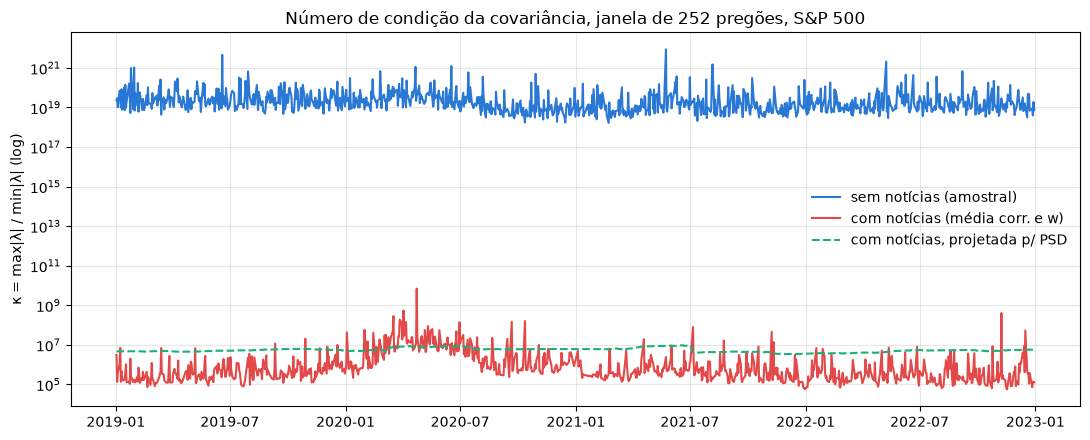

dias em que a covariância com notícias NÃO é PSD: 100.0%


In [38]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(serie.index, serie["cond_sem"], color="#2a78d6", lw=1.5, label="sem notícias (amostral)")
ax.plot(serie.index, serie["cond_com"], color="#e34948", lw=1.5, label="com notícias (média corr. e w)")
ax.plot(serie.index, serie["cond_com_psd"], color="#1baf7a", lw=1.5, ls="--", label="com notícias, projetada p/ PSD")
ax.set_yscale("log")
ax.set_ylabel("κ = max|λ| / min|λ| (log)")
ax.set_title(f"Número de condição da covariância, janela de {inSample} pregões, S&P 500")
ax.grid(alpha=0.3, which="both")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print(f"dias em que a covariância com notícias NÃO é PSD: {(serie['lambda_min_com'] < 0).mean():.1%}")

## Três caminhos para a covariância sem notícias ser inversível

Com ~350–475 ações e 251 retornos, a covariância amostral é singular (posto ≤ 250) e o κ da seção
anterior é infinito numérico. Aqui o mesmo processo com: (1) só as 100 ações com mais eventos no grafo
na janela; (2) janela de 504 pregões; (3) Ledoit-Wolf (alvo identidade) antes das notícias.

In [39]:
# Os três caminhos para a covariância sem notícias ser inversível. Mesmo processo do loop
# acima; muda só o universo, a janela ou o estimador:
#   "universo 100": as 100 ações (do S&P 500 com cobertura) com mais eventos no grafo na janela
#   "janela 504":   504 pregões (~2 anos) em vez de 252; tuplas também dos 504 pregões
#   "Ledoit-Wolf":  cov = LW com alvo identidade (Ledoit e Wolf, 2004), aplicado antes das notícias
from newsmanager.portfolio import estimators as est

conta_ev = pd.concat([ev_all[["dt", "src"]].rename(columns={"src": "tk"}),
                      ev_all[["dt", "dst"]].rename(columns={"dst": "tk"})]).sort_values("dt")


def serie_kappa(n_dias=252, top=None, lw=False):
    linhas, t0 = [], time.time()
    for t in dias:
        antes = calendario[calendario < t].iloc[-n_dias:]
        tk = [s for s in membros(t) if s in retornos.columns]
        ok = retornos.reindex(index=antes, columns=tk).notna().mean() >= 0.95
        tk = list(ok.index[ok])
        if top:                                   # as `top` com mais eventos na janela (só datas < t)
            c = conta_ev[(conta_ev["dt"] >= antes.iloc[0]) & (conta_ev["dt"] < t)]["tk"].value_counts()
            tk = sorted(c.reindex(tk).fillna(0).sort_values(ascending=False, kind="stable").index[:top])
        ret = px_all.reindex(index=antes, columns=tk).ffill().bfill().pct_change().dropna()
        ret = ret.loc[:, ret.std() > 0]
        cov = ret.cov()
        if lw:
            cov = pd.DataFrame(est.lw_identity(ret.values), index=cov.index, columns=cov.columns)
        sd = np.sqrt(np.diag(cov.values))
        corr = cov / np.outer(sd, sd)
        tup = ev_all[(ev_all["dt"] >= antes.iloc[0]) & (ev_all["dt"] < t)]
        tup = tup[tup["src"].isin(cov.index) & tup["dst"].isin(cov.index)]
        W = matriz_w(tup, list(cov.index))
        corr_n = corr.where(W == 0, (corr + W) / 2)
        cov_n = corr_para_cov(corr_n, cov)
        cov_psd = corr_para_cov(pd.DataFrame(nearest_corr(corr_n.values), index=corr.index, columns=corr.columns), cov)
        linhas.append({"date": t, "p": len(cov), "T": len(ret), "pares_noticia": int((W.values != 0).sum() // 2),
                       "cond_sem": kappa(cov.values), "cond_com": kappa(cov_n.values),
                       "cond_com_psd": kappa(cov_psd.values), "lambda_min_com": np.linalg.eigvalsh(cov_n.values)[0]})
    print(f"  {len(linhas)} pregões em {time.time() - t0:.0f}s")
    return pd.DataFrame(linhas).set_index("date")


caminhos = {"universo 100": dict(top=100), "janela 504": dict(n_dias=504), "Ledoit-Wolf": dict(lw=True)}
series = {}
for nome, kw in caminhos.items():
    print(nome)
    series[nome] = serie_kappa(**kw)
    series[nome].to_parquet(ROOT / f"data/marts/stability/janela_noticias_sp500_{nome.replace(' ', '_').lower()}.parquet")

resumo = pd.DataFrame({nome: {"ações (mediana)": s["p"].median(), "retornos": s["T"].median(),
                              "pares com notícia": s["pares_noticia"].median(),
                              "κ sem notícias": s["cond_sem"].median(), "κ com notícias": s["cond_com"].median(),
                              "κ com notícias (PSD)": s["cond_com_psd"].median(),
                              "com/sem (mediana diária)": (s["cond_com"] / s["cond_sem"]).median(),
                              "dias com/sem > 1": (s["cond_com"] > s["cond_sem"]).mean(),
                              "dias não PSD com notícias": (s["lambda_min_com"] < 0).mean()}
                       for nome, s in series.items()})
resumo

universo 100
  1008 pregões em 16s
janela 504
  1008 pregões em 62s
Ledoit-Wolf
  1008 pregões em 60s


,universo 100,janela 504,Ledoit-Wolf
ações (mediana),1.000000e+02,3.580000e+02,3.580000e+02
retornos,2.510000e+02,5.030000e+02,2.510000e+02
pares com notícia,4.245000e+02,1.011500e+03,6.800000e+02
κ sem notícias,1.793009e+03,9.645746e+04,2.061450e+03
κ com notícias,6.886308e+03,1.383052e+05,6.592610e+04
κ com notícias (PSD),1.136416e+06,4.895385e+06,3.618866e+06
com/sem (mediana diária),2.495512e+00,9.081572e-01,4.717088e+01
dias com/sem > 1,9.037698e-01,4.771825e-01,1.000000e+00
dias não PSD com notícias,1.000000e+00,1.000000e+00,1.000000e+00


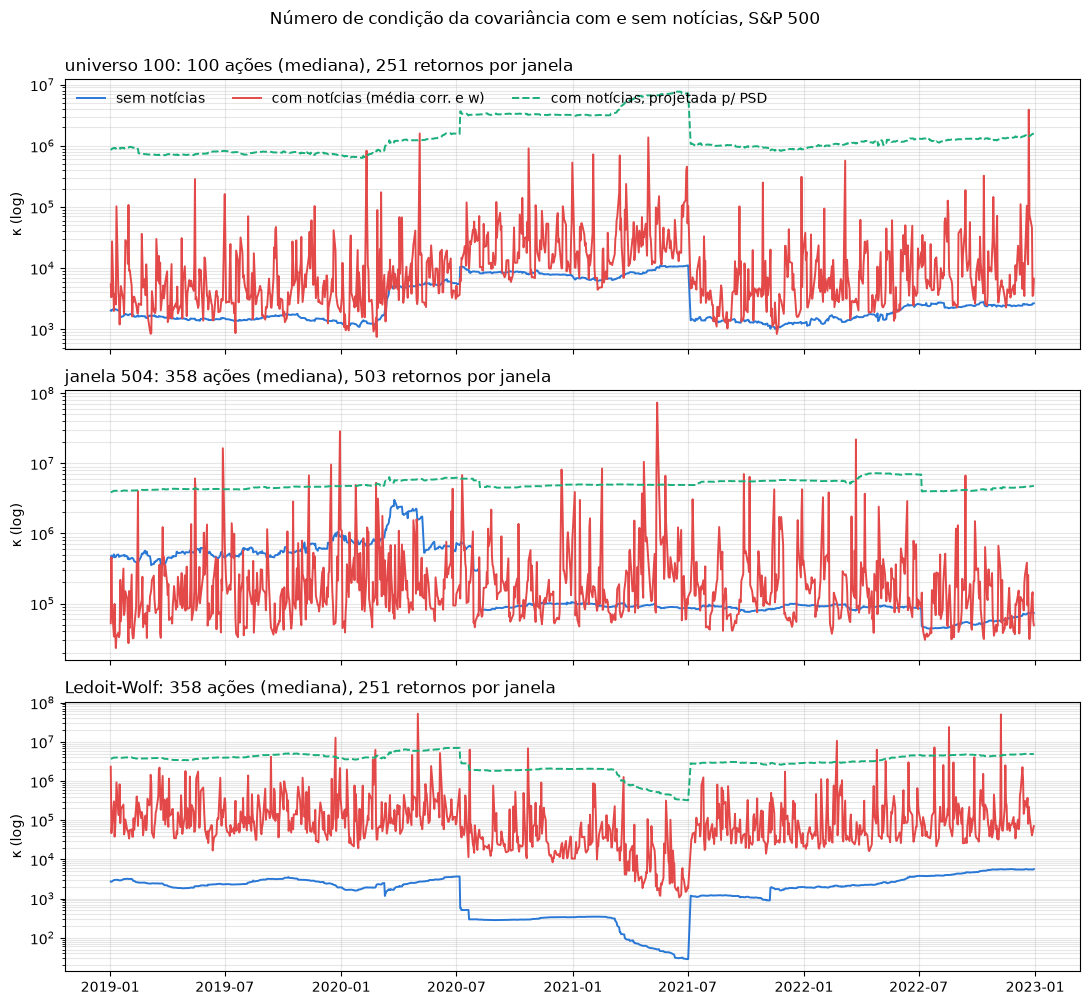

In [40]:
fig, axs = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, (nome, s) in zip(axs, series.items()):
    ax.plot(s.index, s["cond_sem"], color="#2a78d6", lw=1.4, label="sem notícias")
    ax.plot(s.index, s["cond_com"], color="#e34948", lw=1.4, label="com notícias (média corr. e w)")
    ax.plot(s.index, s["cond_com_psd"], color="#1baf7a", lw=1.4, ls="--", label="com notícias, projetada p/ PSD")
    ax.set_yscale("log")
    ax.set_title(f"{nome}: {s['p'].median():.0f} ações (mediana), {s['T'].median():.0f} retornos por janela", loc="left")
    ax.set_ylabel("κ (log)")
    ax.grid(alpha=0.3, which="both")
axs[0].legend(frameon=False, ncol=3, loc="upper left")
fig.suptitle("Número de condição da covariância com e sem notícias, S&P 500", y=1.0)
plt.tight_layout()
plt.show()

## Shrinkage para o alvo de notícias

Em vez de trocar a correlação dos pares com notícia, encolhe-se a covariância amostral para um alvo
válido (seção 4.3 do método): Σ̂ = δ·D^½ R D^½ + (1−δ)·S, com δ ótimo de Ledoit-Wolf.
Alvo sem notícias: correlação constante r̄ (LW corr. constante). Alvo com notícias: r̄, mas
(r̄ + w)/2 nos pares com tupla, projetado para PSD. Placebo: o mesmo com as notícias embaralhadas entre as ações.

In [41]:
# Shrinkage para um alvo de notícias (o desenho da seção 4.3 do método, em versão simples):
#   alvo sem notícias:  R0 = correlação constante r̄ (média das correlações da janela) -> LW corr. constante
#   alvo com notícias:  R_N = R0, mas nos pares com tupla (r̄ + w médio)/2; projetado para PSD
#   placebo:            o mesmo R_N com as ações embaralhadas na matriz W (notícia no par errado)
#   Σ̂ = δ·D^½ R D^½ + (1−δ)·S, δ ótimo de Ledoit-Wolf para cada alvo (est.shrink_to_corr).
# Σ̂ é combinação convexa de duas matrizes PSD: é sempre PSD.
rng = np.random.default_rng(7)


def serie_shrink(n_dias=252, top=None):
    linhas, t0 = [], time.time()
    for t in dias:
        antes = calendario[calendario < t].iloc[-n_dias:]
        tk = [s for s in membros(t) if s in retornos.columns]
        ok = retornos.reindex(index=antes, columns=tk).notna().mean() >= 0.95
        tk = list(ok.index[ok])
        if top:
            c = conta_ev[(conta_ev["dt"] >= antes.iloc[0]) & (conta_ev["dt"] < t)]["tk"].value_counts()
            tk = sorted(c.reindex(tk).fillna(0).sort_values(ascending=False, kind="stable").index[:top])
        ret = px_all.reindex(index=antes, columns=tk).ffill().bfill().pct_change().dropna()
        ret = ret.loc[:, ret.std() > 0]
        X, p = ret.values, ret.shape[1]
        corr = np.corrcoef(X, rowvar=False)
        rbar = (corr.sum() - p) / (p * (p - 1))
        tup = ev_all[(ev_all["dt"] >= antes.iloc[0]) & (ev_all["dt"] < t)]
        tup = tup[tup["src"].isin(ret.columns) & tup["dst"].isin(ret.columns)]
        W = matriz_w(tup, list(ret.columns)).values

        def alvo(W):
            R = np.where(W != 0, (rbar + W) / 2, rbar)
            np.fill_diagonal(R, 1.0)
            return nearest_corr(R)

        perm = rng.permutation(p)
        S_cc, d_cc = est.lw_const_corr(X, return_delta=True)
        S_n, d_n = est.shrink_to_corr(X, alvo(W), return_delta=True)
        S_pl, d_pl = est.shrink_to_corr(X, alvo(W[np.ix_(perm, perm)]), return_delta=True)
        linhas.append({"date": t, "p": p, "T": len(X), "pares_noticia": int((W != 0).sum() // 2),
                       "cond_amostral": kappa(np.cov(X, rowvar=False)), "cond_lw_cc": kappa(S_cc),
                       "cond_noticias": kappa(S_n), "cond_placebo": kappa(S_pl),
                       "delta_lw_cc": d_cc, "delta_noticias": d_n, "delta_placebo": d_pl,
                       "lambda_min_noticias": np.linalg.eigvalsh(S_n)[0]})
    print(f"  {len(linhas)} pregões em {time.time() - t0:.0f}s")
    return pd.DataFrame(linhas).set_index("date")


caminhos_shrink = {"S&P 500, janela 252": dict(), "universo 100": dict(top=100), "janela 504": dict(n_dias=504)}
series_shrink = {}
for nome, kw in caminhos_shrink.items():
    print(nome)
    series_shrink[nome] = s = serie_shrink(**kw)
    s.to_parquet(ROOT / f"data/marts/stability/shrink_noticias_sp500_{nome.split(',')[0].replace(' ', '_').replace('&', '').lower()}.parquet")

resumo_shrink = pd.DataFrame({nome: {
    "ações / retornos": f"{s['p'].median():.0f} / {s['T'].median():.0f}",
    "κ amostral": f"{s['cond_amostral'].median():.3g}",
    "κ LW corr. constante (sem notícias)": f"{s['cond_lw_cc'].median():.0f}",
    "κ alvo de notícias": f"{s['cond_noticias'].median():.0f}",
    "κ placebo": f"{s['cond_placebo'].median():.0f}",
    "notícias / LW cc (mediana diária)": f"{(s['cond_noticias'] / s['cond_lw_cc']).median():.3f}",
    "dias notícias < LW cc": f"{(s['cond_noticias'] < s['cond_lw_cc']).mean():.1%}",
    "placebo / LW cc (mediana diária)": f"{(s['cond_placebo'] / s['cond_lw_cc']).median():.3f}",
    "δ médio LW cc / notícias / placebo": f"{s['delta_lw_cc'].mean():.2f} / {s['delta_noticias'].mean():.2f} / {s['delta_placebo'].mean():.2f}",
    "dias não PSD (notícias)": f"{(s['lambda_min_noticias'] < 0).mean():.1%}"}
    for nome, s in series_shrink.items()})
resumo_shrink

S&P 500, janela 252
  1008 pregões em 86s
universo 100
  1008 pregões em 19s
janela 504
  1008 pregões em 102s


,"S&P 500, janela 252",universo 100,janela 504
ações / retornos,358 / 251,100 / 251,358 / 503
κ amostral,1.45e+19,1.79e+03,9.65e+04
κ LW corr. constante (sem notícias),3227,601,2352
κ alvo de notícias,10833,744,6191
κ placebo,11378,880,5903
notícias / LW cc (mediana diária),3.257,1.489,2.677
dias notícias < LW cc,0.0%,28.9%,0.0%
placebo / LW cc (mediana diária),3.516,1.543,2.461
δ médio LW cc / notícias / placebo,0.26 / 0.26 / 0.26,0.29 / 0.25 / 0.26,0.27 / 0.29 / 0.28
dias não PSD (notícias),0.0%,0.0%,0.0%


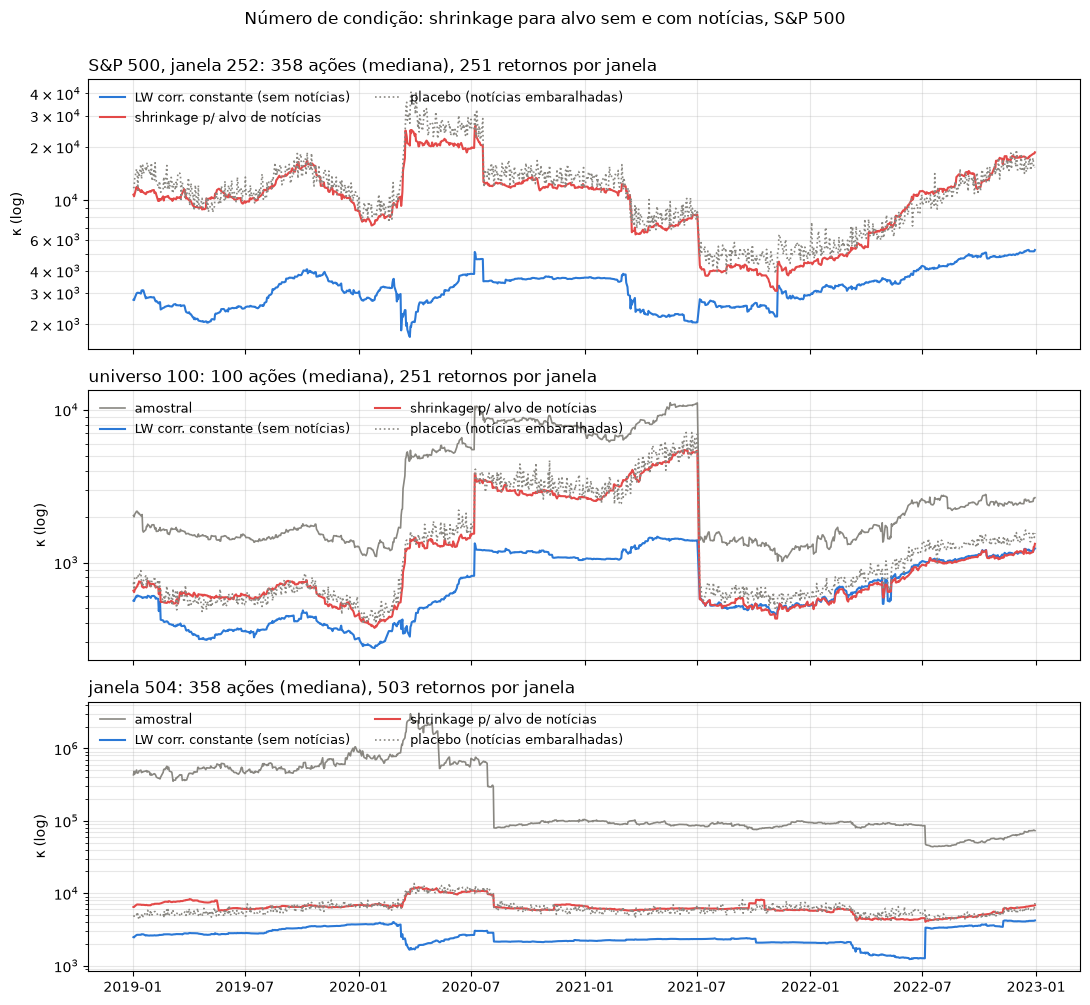

In [42]:
fig, axs = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, (nome, s) in zip(axs, series_shrink.items()):
    if s["cond_amostral"].median() < 1e8:          # amostral só quando é inversível
        ax.plot(s.index, s["cond_amostral"], color="#898781", lw=1.2, label="amostral")
    ax.plot(s.index, s["cond_lw_cc"], color="#2a78d6", lw=1.5, label="LW corr. constante (sem notícias)")
    ax.plot(s.index, s["cond_noticias"], color="#e34948", lw=1.5, label="shrinkage p/ alvo de notícias")
    ax.plot(s.index, s["cond_placebo"], color="#898781", lw=1.2, ls=":", label="placebo (notícias embaralhadas)")
    ax.set_yscale("log")
    ax.set_title(f"{nome}: {s['p'].median():.0f} ações (mediana), {s['T'].median():.0f} retornos por janela", loc="left")
    ax.set_ylabel("κ (log)")
    ax.grid(alpha=0.3, which="both")
    ax.legend(frameon=False, ncol=2, loc="upper left", fontsize=9)
fig.suptitle("Número de condição: shrinkage para alvo sem e com notícias, S&P 500", y=1.0)
plt.tight_layout()
plt.show()

## Outras regras para o alvo, com conexões diretas e indiretas

**Indireta**: AAPL–FED–NVDA conta como notícia AAPL–NVDA. Cada ação vira um vetor de exposição aos outros
nós do grafo na janela (Σ|w| × IDF); a ligação indireta é o cosseno entre os vetores.

| regra | alvo de correlação |
|---|---|
| média direta | (r̄ + w)/2 nos pares com tupla |
| média direta+indireta | idem, com o cosseno quando não há tupla direta |
| regressão direta | tanh(a + b·w + c·1[tupla]), MQO na correlação da janela |
| regressão direta+indireta | idem + d·cosseno |
| exposição (PSD) | (1−λ)·r̄ + λ·G (G = cossenos, PSD por construção) |

Σ̂ = δ·alvo + (1−δ)·S com δ ótimo de Ledoit-Wolf. Comparação com o LW correlação constante (alvo sem
notícias) e com o placebo de cada regra, em κ e no erro da correlação contra a realizada nos
`rebalance_frequency` pregões seguintes. Leva ~10 min.

In [50]:
# Regras para o alvo de notícias, com conexões diretas e indiretas.
#
# Sinais de notícia na janela (só eventos com data < t):
#   D (direto):   w médio das tuplas entre as duas ações (AAPL-NVDA); 0 sem tupla
#   I (indireto): AAPL-FED-NVDA conta como notícia AAPL-NVDA. Cada ação vira um vetor de exposição
#                 B_ik = Σ|w| dos eventos com o nó k (Fed, petróleo, China, outras empresas...)
#                 × IDF log(p / nº de ações ligadas a k); I_ij = cos(B_i, B_j). Nós que ligam
#                 quase todas as ações (S&P 500) pesam pouco; os ligados a uma só ação não contam.
#
# Regras (alvo de correlação R; Σ̂ = δ·D^½ R D^½ + (1−δ)·S, δ ótimo de Ledoit-Wolf):
#   média direta            (r̄ + D)/2 nos pares com tupla direta (a regra anterior)
#   média direta+indireta   idem com s = D se há tupla direta, senão I
#   regressão direta        z = a + b·D + c·1[D≠0], MQO na correlação amostral da janela (Fisher z), R = tanh(z)
#   regressão direta+ind.   z = a + b·D + c·1[D≠0] + d·I
#   exposição (PSD)         R = (1−λ)·r̄ + λ·G, G = matriz de cossenos (sempre PSD, diagonal 1);
#                           λ = MQO de (ρ − r̄) em (G − r̄) nos pares, cortado em [0, 1]
# As regressões calibram a escala na própria janela (o alvo passa a depender dos mesmos retornos).
# Alvo não PSD é projetado (nearest_corr); a coluna proj_* registra quando isso acontece.
# Placebo de cada regra: D, I e G com as ações embaralhadas.
# Avaliação fora da amostra: erro quadrático médio entre a correlação de Σ̂ e a correlação
# realizada nos `rebalance_frequency` pregões seguintes (só para avaliar; Σ̂ não usa esses dados).
import scipy.sparse as sps

lig = pd.concat([eventos[["dt", "src", "dst", "w"]].rename(columns={"src": "acao", "dst": "outro"}),
                 eventos[["dt", "dst", "src", "w"]].rename(columns={"dst": "acao", "src": "outro"})])
lig = lig[(lig["acao"] != lig["outro"]) & lig["acao"].isin(px_all.columns)]
lig = lig.assign(dt=pd.to_datetime(lig["dt"]), absw=lig["w"].abs()).sort_values("dt").reset_index(drop=True)
lig_dt = lig["dt"].to_numpy()


def exposicao(tk, ini, t):
    """Matriz de cossenos G (p x p) das exposições das ações `tk` aos outros nós na janela [ini, t)."""
    a, b = np.searchsorted(lig_dt, np.datetime64(ini)), np.searchsorted(lig_dt, np.datetime64(t))
    L = lig.iloc[a:b]
    L = L[L["acao"].isin(tk)]
    p = len(tk)
    G = np.eye(p)
    if L.empty:
        return G
    agg = L.groupby(["acao", "outro"], sort=False)["absw"].sum().reset_index()
    df = agg.groupby("outro")["acao"].nunique()
    agg["x"] = agg["absw"] * np.log(p / agg["outro"].map(df))
    agg = agg[agg["x"] > 0]
    pos = {s: k for k, s in enumerate(tk)}
    cols = {o: k for k, o in enumerate(agg["outro"].unique())}
    B = sps.csr_matrix((agg["x"], (agg["acao"].map(pos), agg["outro"].map(cols))), shape=(p, len(cols)))
    nrm = np.sqrt(np.asarray(B.multiply(B).sum(axis=1)).ravel())
    B = sps.diags(np.divide(1, nrm, out=np.zeros(p), where=nrm > 0)) @ B
    G = (B @ B.T).toarray()
    np.fill_diagonal(G, 1.0)
    return G


def regras(D, G, rbar, z, iu):
    """Alvos (antes da projeção) de cada regra."""
    p = len(D)
    I = G.copy()
    np.fill_diagonal(I, 0.0)
    base = np.full((p, p), rbar)
    out = {}
    out["média direta"] = np.where(D != 0, (rbar + D) / 2, base)
    s = np.where(D != 0, D, I)
    out["média direta+indireta"] = np.where(s != 0, (rbar + s) / 2, base)
    for nome, cols in (("regressão direta", [D[iu], (D[iu] != 0)]),
                       ("regressão direta+indireta", [D[iu], (D[iu] != 0), I[iu]])):
        X = np.column_stack([np.ones(len(iu[0])), *cols])
        coef, *_ = np.linalg.lstsq(X, z[iu], rcond=None)
        R = np.eye(p)
        R[iu] = np.tanh(X @ coef)
        out[nome] = R + np.triu(R, 1).T
    g, rho = G[iu] - rbar, np.tanh(z[iu]) - rbar
    lam = float(np.clip((g @ rho) / (g @ g), 0, 1)) if g @ g > 0 else 0.0
    out["exposição (PSD)"] = (1 - lam) * base + lam * G
    for R in out.values():
        np.fill_diagonal(R, 1.0)
    return out, lam


NOMES_REGRAS = ["média direta", "média direta+indireta", "regressão direta", "regressão direta+indireta",
                "exposição (PSD)"]


def serie_regras(n_dias=252, top=None, seed=7):
    rng = np.random.default_rng(seed)
    linhas, t0 = [], time.time()
    for k, t in enumerate(dias):
        antes = calendario[calendario < t].iloc[-n_dias:]
        depois = calendario[calendario >= t].iloc[:rebalance_frequency]
        tk = [s for s in membros(t) if s in retornos.columns]
        ok = retornos.reindex(index=antes, columns=tk).notna().mean() >= 0.95
        tk = list(ok.index[ok])
        if top:
            c = conta_ev[(conta_ev["dt"] >= antes.iloc[0]) & (conta_ev["dt"] < t)]["tk"].value_counts()
            tk = sorted(c.reindex(tk).fillna(0).sort_values(ascending=False, kind="stable").index[:top])
        ret = px_all.reindex(index=antes, columns=tk).ffill().bfill().pct_change().dropna()
        ret = ret.loc[:, ret.std() > 0]
        tk = list(ret.columns)
        X, p = ret.values, len(tk)
        corr = np.corrcoef(X, rowvar=False)
        iu = np.triu_indices(p, 1)
        rbar = corr[iu].mean()
        z = np.arctanh(np.clip(corr, -0.999, 0.999))
        tup = ev_all[(ev_all["dt"] >= antes.iloc[0]) & (ev_all["dt"] < t)]
        D = matriz_w(tup[tup["src"].isin(tk) & tup["dst"].isin(tk)], tk).values
        G = exposicao(tk, antes.iloc[0], t)
        perm = rng.permutation(p)
        alvos, lam = regras(D, G, rbar, z, iu)
        alvos_pl, lam_pl = regras(D[np.ix_(perm, perm)], G[np.ix_(perm, perm)], rbar, z, iu)

        # correlação realizada nos pregões seguintes (só avaliação)
        fut = px_all.reindex(index=pd.DatetimeIndex([antes.iloc[-1], *depois]), columns=tk).ffill().pct_change().iloc[1:]
        Cf = fut.corr().values
        okf = np.isfinite(Cf[iu])

        def avalia(S):
            sd = np.sqrt(np.diag(S))
            C = S / np.outer(sd, sd)
            return kappa(S), float(np.mean((C[iu][okf] - Cf[iu][okf]) ** 2))

        row = {"date": t, "p": p, "pares_diretos": int((D[iu] != 0).sum()),
               "pares_indiretos": int((G[iu] > 0).sum()), "lambda_exposicao": lam}
        S_cc, d_cc = est.lw_const_corr(X, return_delta=True)
        row["cond|LW corr. constante"], row["mse|LW corr. constante"] = avalia(S_cc)
        row["delta|LW corr. constante"] = d_cc
        row["cond|amostral"], row["mse|amostral"] = avalia(np.cov(X, rowvar=False))
        S_id, d_id = est.lw_identity(X, return_delta=True)
        row["cond|LW identidade"], row["mse|LW identidade"] = avalia(S_id)
        row["delta|LW identidade"] = d_id
        for tag, conj in (("", alvos), (" [placebo]", alvos_pl)):
            for nome, R in conj.items():
                lmin = np.linalg.eigvalsh(R)[0]
                S, d = est.shrink_to_corr(X, nearest_corr(R) if lmin < 1e-4 else R, return_delta=True)
                row[f"cond|{nome}{tag}"], row[f"mse|{nome}{tag}"] = avalia(S)
                row[f"delta|{nome}{tag}"], row[f"proj|{nome}{tag}"] = d, float(lmin < 1e-4)
        linhas.append(row)
        if (k + 1) % 200 == 0:
            print(f"  {t:%Y-%m-%d} ({k + 1}/{len(dias)}, {time.time() - t0:.0f}s)")
    print(f"  {len(linhas)} pregões em {time.time() - t0:.0f}s")
    return pd.DataFrame(linhas).set_index("date")


def resumo_regras(s):
    rows = {}
    for nome in ["amostral", "LW identidade", "LW corr. constante", *NOMES_REGRAS]:
        r = {"κ mediano": s[f"cond|{nome}"].median(),
             "κ / LW cc (mediana diária)": (s[f"cond|{nome}"] / s["cond|LW corr. constante"]).median(),
             "erro corr. fora da amostra (×1000)": 1000 * s[f"mse|{nome}"].mean(),
             "erro / LW cc": s[f"mse|{nome}"].mean() / s["mse|LW corr. constante"].mean()}
        if nome in NOMES_REGRAS:
            pl = f"{nome} [placebo]"
            r.update({"κ / LW cc placebo": (s[f"cond|{pl}"] / s["cond|LW corr. constante"]).median(),
                      "erro / LW cc placebo": s[f"mse|{pl}"].mean() / s["mse|LW corr. constante"].mean(),
                      "δ médio": s[f"delta|{nome}"].mean(), "dias com alvo projetado": s[f"proj|{nome}"].mean()})
        elif nome.startswith("LW"):
            r["δ médio"] = s[f"delta|{nome}"].mean()
        rows[nome] = r
    return pd.DataFrame(rows).T

In [49]:
caminhos_regras = {"S&P 500, janela 252": dict(), "universo 100": dict(top=100)}
series_regras, resumos_regras = {}, {}
for nome, kw in caminhos_regras.items():
    print(nome)
    series_regras[nome] = s = serie_regras(**kw)
    s.to_parquet(ROOT / f"data/marts/stability/regras_noticias_{'sp500' if not kw else 'top100'}.parquet")
    resumos_regras[nome] = resumo_regras(s)
pd.concat(resumos_regras).round(3)

S&P 500, janela 252
  2019-10-16 (200/1008, 95s)
  2020-08-03 (400/1008, 186s)
  2021-05-19 (600/1008, 239s)
  2022-03-04 (800/1008, 294s)
  2022-12-19 (1000/1008, 354s)
  1008 pregões em 357s
universo 100
  2019-10-16 (200/1008, 13s)
  2020-08-03 (400/1008, 25s)
  2021-05-19 (600/1008, 37s)
  2022-03-04 (800/1008, 50s)
  2022-12-19 (1000/1008, 64s)
  1008 pregões em 64s


κ mediano  κ / LW cc (mediana diária)  erro corr. fora da amostra (×1000)  erro / LW cc  δ médio  κ / LW cc placebo  erro / LW cc placebo  \
S&P 500, janela 252 amostral                   1.447171e+19                4.639470e+15                              86.084         1.018      NaN                NaN                   NaN   
                    LW corr. constante         3.227141e+03                1.000000e+00                              84.552         1.000    0.260                NaN                   NaN   
                    média direta               1.083319e+04                3.257000e+00                              83.158         0.984    0.264              3.516                 0.985   
                    média direta+indireta      1.337175e+04                4.062000e+00                              79.831         0.944    0.246              4.550                 0.952   
                    regressão direta           5.507059e+03                1.785000e+00                              85.042         1.006    0.255              1.036                 1.006   
                    regressão direta+indireta  6.885957e+03                2.101000e+00                              84.985         1.005    0.259              1.040                 1.006   
                    exposição (PSD)            3.211257e+03                9.960000e-01                              84.544         1.000    0.261              1.000                 1.000   
universo 100        amostral                   1.793009e+03                3.909000e+00                              89.691         1.035      NaN                NaN                   NaN   
                    LW corr. constante         6.013320e+02                1.000000e+00                              86.641         1.000    0.287                NaN                   NaN   
                    média direta               7.436490e+02                1.489000e+00                              83.979         0.969    0.252              1.534                 0.965   
                    média direta+indireta      8.478850e+02                1.642000e+00                              80.618         0.930    0.244              1.614                 0.927   
                    regressão direta           8.458690e+02                1.357000e+00                              87.293         1.008    0.291              1.028                 1.010   
                    regressão direta+indireta  8.580240e+02                1.317000e+00                              87.095         1.005    0.297              1.030                 1.010   
                    exposição (PSD)            5.919650e+02                9.910000e-01                              86.557         0.999    0.289              1.000                 1.000   

                                               dias com alvo projetado  
S&P 500, janela 252 amostral                                       NaN  
                    LW corr. constante                             NaN  
                    média direta                                 1.000  
                    média direta+indireta                        1.000  
                    regressão direta                             0.795  
                    regressão direta+indireta                    0.686  
                    exposição (PSD)                              0.000  
universo 100        amostral                                       NaN  
                    LW corr. constante                             NaN  
                    média direta                                 1.000  
                    média direta+indireta                        1.000  
                    regressão direta                             0.668  
                    regressão direta+indireta                    0.485  
                    exposição (PSD)                              0.000

aviso: ['LW identidade'] não está nas séries em memória; rode de novo a célula do loop (caminhos_regras = ...)


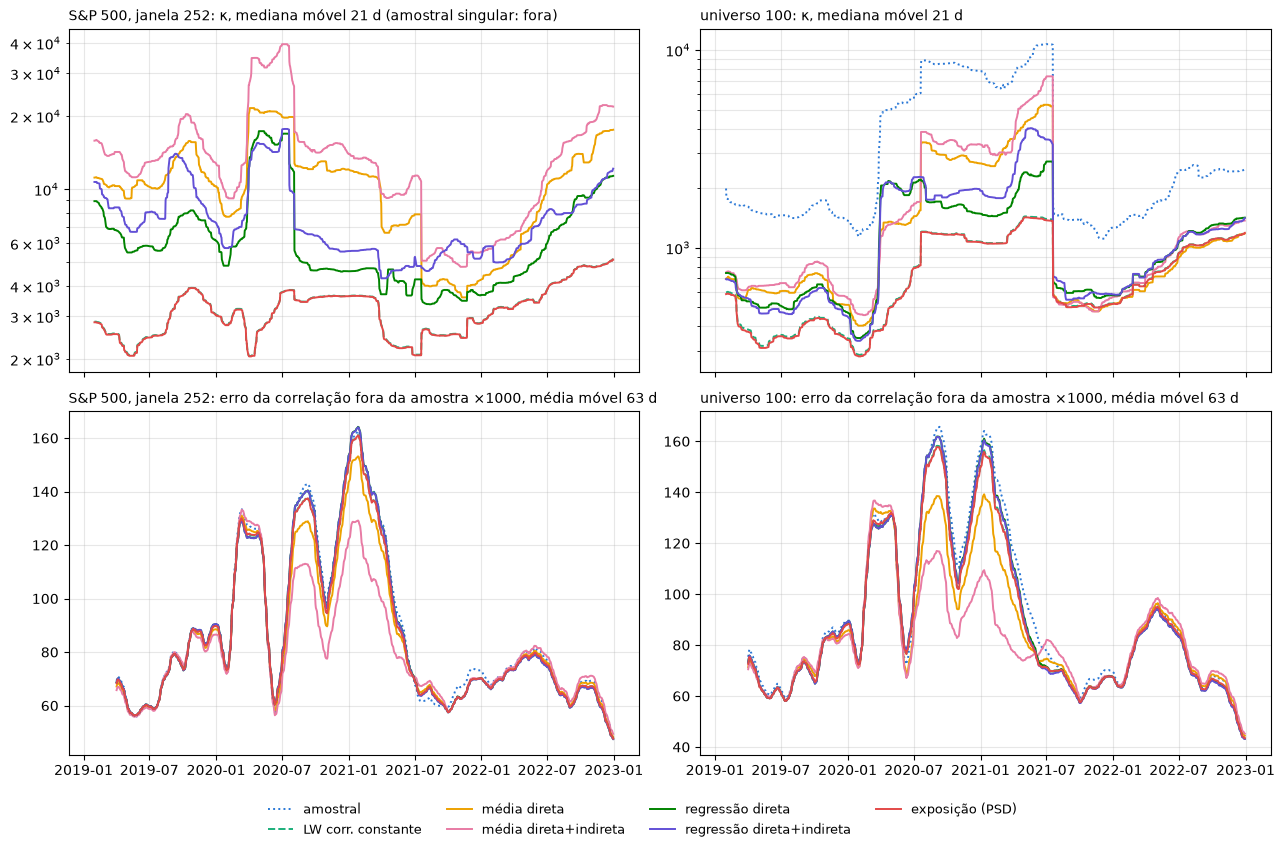

In [54]:
import matplotlib.pyplot as plt

# séries calculadas antes do LW identidade entrar no loop: rode de novo a célula do loop
faltam = sorted({nome for s in series_regras.values() for nome in ["LW identidade"] if f"cond|{nome}" not in s})
if faltam:
    print(f"aviso: {faltam} não está nas séries em memória; rode de novo a célula do loop (caminhos_regras = ...)")

# níveis absolutos: amostral e Ledoit-Wolf puro (alvo identidade) como referências, LW corr. constante
# (alvo sem notícias) e as cinco regras com notícias. Cores na ordem fixa da paleta categórica.
ordem = ["amostral", "LW identidade", "LW corr. constante", *NOMES_REGRAS]
cores = dict(zip(ordem, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]))
estilo = {"amostral": ":", "LW identidade": "--", "LW corr. constante": "--"}
fig, axs = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
for col, (nome, s) in enumerate(series_regras.items()):
    for m in [m for m in ordem if f"cond|{m}" in s]:
        if not (m == "amostral" and s["cond|amostral"].median() > 1e8):   # amostral singular: κ infinito
            axs[0, col].plot(s.index, s[f"cond|{m}"].rolling(21).median(), color=cores[m],
                             ls=estilo.get(m, "-"), lw=1.4, label=m)
        axs[1, col].plot(s.index, 1000 * s[f"mse|{m}"].rolling(63).mean(), color=cores[m],
                         ls=estilo.get(m, "-"), lw=1.4, label=m)
    axs[0, col].set_yscale("log")
    nota = " (amostral singular: fora)" if s["cond|amostral"].median() > 1e8 else ""
    axs[0, col].set_title(f"{nome}: κ, mediana móvel 21 d{nota}", loc="left", fontsize=10)
    axs[1, col].set_title(f"{nome}: erro da correlação fora da amostra ×1000, média móvel 63 d", loc="left", fontsize=10)
    for ax in axs[:, col]:
        ax.grid(alpha=0.3, which="both")
handles, labels = axs[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()